# Predictive Pharmacovigilance — Integrating FAERS Signals with Molecular Data
**B Aditya (SE23UCAB002) | AI in Pharmacovigilance | Assignment-2**

This notebook continues directly from Assignment-1. It takes the FAERS
2025Q3 drug-ADR signal table produced there, adds the Empirical Bayes
Geometric Mean (EBGM) signal-detection score (not computed in
Assignment-1), selects a set of well-characterized small-molecule drugs,
maps them to canonical SMILES, engineers chemical + clinical + demographic
features, and trains/compares machine-learning models to predict whether
a drug-ADR pair is a **high-risk signal (EBGM >= 3)**.

In [ ]:
# Project setup: define local folders and make sure the required FAERS inputs exist.
# This notebook builds on Assignment-1 outputs, so we copy the generated signal file
# and the raw ASCII tables into the local project workspace when they are not already present.
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.special import gammaln, digamma
from scipy.stats import gamma as gamma_dist

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, MACCSkeys, AllChem

from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                              roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
np.random.seed(42)

# Project path setup: this notebook is expected to live in the assignment directory.
# The Assignment-1 files are stored one level above in a sibling folder.
base_dir = Path.cwd()
source_dir = (base_dir.parent / "BAditya_assignment1").resolve()
local_data_dir = base_dir / "data"
local_results_dir = base_dir / "results"
local_figures_dir = base_dir / "figures"
local_ascii_dir = base_dir / "ascii_data" / "faers_ascii_2025q3" / "ASCII"

# Ensure the project folders exist before writing outputs.
for directory in [local_data_dir, local_results_dir, local_figures_dir]:
    directory.mkdir(exist_ok=True, parents=True)

# Copy the generated FAERS signal table from the Assignment-1 project if it exists.
faers_src = source_dir / "results" / "FAERS_signals.csv"
faers_dst = local_data_dir / "FAERS_signals.csv"
if faers_src.exists() and not faers_dst.exists():
    shutil.copy2(faers_src, faers_dst)

# Copy the raw FAERS ASCII data folder if needed.
ascii_src = source_dir / "faers_ascii_2025q3" / "ASCII"
if ascii_src.exists() and not local_ascii_dir.exists():
    shutil.copytree(ascii_src, local_ascii_dir, dirs_exist_ok=True)

# Fail loudly if required inputs are absent; this helps prevent silent errors later.
if not faers_dst.exists():
    raise FileNotFoundError(f"Missing FAERS input: {faers_dst}\nExpected to find the generated signal file in {faers_src}.")

if not local_ascii_dir.exists():
    raise FileNotFoundError(f"Missing FAERS ASCII directory: {local_ascii_dir}\nExpected to find it in {ascii_src}.")

print(f"Project root: {base_dir}")
print(f"FAERS source file ready: {faers_dst}")
print(f"ASCII source directory ready: {local_ascii_dir}")


Project root: /Users/aditya/Desktop/sem-7/AI in pharmacovigilance/Baditya_assignment2
FAERS source file ready: /Users/aditya/Desktop/sem-7/AI in pharmacovigilance/Baditya_assignment2/data/FAERS_signals.csv
ASCII source directory ready: /Users/aditya/Desktop/sem-7/AI in pharmacovigilance/Baditya_assignment2/ascii_data/faers_ascii_2025q3/ASCII


## Part 1 — Compute EBGM from the Assignment-1 FAERS signal table

Assignment-1's `FAERS_signals.csv` has PRR, ROR, chi-square and Fisher's
exact p-values for 95,252 drug-ADR pairs, but **not EBGM** (the assignment
brief requires it). EBGM is computed here using DuMouchel's (1999)
**Multi-item Gamma Poisson Shrinker (MGPS)** — the standard empirical-Bayes
shrinkage estimator used alongside PRR/ROR in real pharmacovigilance
systems (FDA, WHO-UMC). Unlike PRR/ROR, which can be unstable or infinite
for small/sparse counts, EBGM "shrinks" extreme ratios from rare pairs
toward the overall mean, giving a more conservative, literature-standard
signal score.

Model: each pair's observed count `a` is treated as
$a \sim \text{Poisson}(\lambda \cdot E)$, where $E$ is the expected count
under independence, and $\lambda$ (the true relative-reporting-rate) is
drawn from a **mixture of two Gamma distributions** (one capturing the
bulk of unremarkable pairs, one capturing a heavier-tailed set of real
signals). The 5 mixture hyperparameters are fit by maximum likelihood,
and EBGM is the geometric mean of each pair's posterior distribution.

In [ ]:
# Read the FAERS signal table produced in Assignment-1.
# Each row corresponds to one drug-ADR pair with 2x2 contingency counts (a, b, c, d).
df = pd.read_csv("data/FAERS_signals.csv")
print(f"Loaded {len(df):,} drug-ADR pairs from Assignment-1")

# Extract the four cells of the 2x2 table for each pair.
# a = reports with both drug and ADR, b = drug without ADR, c = ADR without drug, d = neither.
a = df["a"].values.astype(float)
b = df["b"].values.astype(float)
c = df["c"].values.astype(float)
d = df["d"].values.astype(float)
N = a + b + c + d

# Marginal totals: how often the drug appears and how often the ADR appears.
n_drug = a + b
n_adr = a + c
E = n_drug * n_adr / N
n_obs = a

# Negative log-likelihood for a Gamma-Poisson mixture model.
# This is the core MGPS objective used to fit the two Gamma components.
def nb_loglik(n, E, alpha, beta):
    return (gammaln(n + alpha) - gammaln(alpha) - gammaln(n + 1)
            + alpha * np.log(beta / (beta + E))
            + n * np.log(E / (beta + E)))

# Fit a two-component mixture of Gamma distributions for the true reporting rate lambda.
# The mixture allows the model to capture both common background pairs and rarer signals.
def neg_log_likelihood(theta):
    a1, b1, a2, b2, logit_p = theta
    alpha1, beta1, alpha2, beta2 = np.exp(a1), np.exp(b1), np.exp(a2), np.exp(b2)
    p1 = 1 / (1 + np.exp(-logit_p))
    p2 = 1 - p1
    ll1 = nb_loglik(n_obs, E, alpha1, beta1)
    ll2 = nb_loglik(n_obs, E, alpha2, beta2)
    m = np.maximum(ll1 + np.log(p1), ll2 + np.log(p2))
    ll = m + np.log(np.exp(ll1 + np.log(p1) - m) + np.exp(ll2 + np.log(p2) - m))
    return -np.sum(ll)

# Start from a reasonable initialization near a low-shape, low-rate background component
# and a heavier-tailed signal component.
x0 = np.array([np.log(0.2), np.log(0.1), np.log(2.0), np.log(4.0), 0.0])
print("Fitting 2-component Gamma-Poisson mixture (MGPS) via MLE ...")
res = minimize(neg_log_likelihood, x0, method="Nelder-Mead",
                options={"maxiter": 4000, "xatol": 1e-6, "fatol": 1e-6, "adaptive": True})
print("Converged:", res.success, "| -logLik:", res.fun)

# Extract the fitted Gamma mixture parameters.
a1, b1, a2, b2, logit_p = res.x
alpha1, beta1, alpha2, beta2 = np.exp(a1), np.exp(b1), np.exp(a2), np.exp(b2)
p1 = 1 / (1 + np.exp(-logit_p))
p2 = 1 - p1
print(f"alpha1={alpha1:.4f} beta1={beta1:.4f} alpha2={alpha2:.4f} beta2={beta2:.4f} P1={p1:.4f}")


Loaded 95,252 drug-ADR pairs from Assignment-1
Fitting 2-component Gamma-Poisson mixture (MGPS) via MLE ...
Converged: True | -logLik: 364276.0608490091
alpha1=0.5660 beta1=0.0068 alpha2=1.2273 beta2=0.3315 P1=0.2582


In [ ]:
# Compute posterior responsibilities for the two Gamma components.
# Each pair is assigned a weight w1/w2 based on how likely it belongs to the background
# versus the signal-generating mixture component.
ll1 = nb_loglik(n_obs, E, alpha1, beta1)
ll2 = nb_loglik(n_obs, E, alpha2, beta2)
m = np.maximum(ll1 + np.log(p1), ll2 + np.log(p2))
w1 = np.exp(ll1 + np.log(p1) - m) / (np.exp(ll1 + np.log(p1) - m) + np.exp(ll2 + np.log(p2) - m))
w2 = 1 - w1

# Posterior Gamma parameters for the selected component mixture.
# The EBGM score is the expectation of the posterior reporting ratio for each pair.
post_alpha1, post_beta1 = alpha1 + n_obs, beta1 + E
post_alpha2, post_beta2 = alpha2 + n_obs, beta2 + E

elog1 = digamma(post_alpha1) - np.log(post_beta1)
elog2 = digamma(post_alpha2) - np.log(post_beta2)
EBGM = np.exp(w1 * elog1 + w2 * elog2)

# A lower 5th percentile (EB05) is also computed as a conservative signal threshold.
EB05_1 = gamma_dist.ppf(0.05, post_alpha1, scale=1 / post_beta1)
EB05_2 = gamma_dist.ppf(0.05, post_alpha2, scale=1 / post_beta2)
EB05 = np.where(w1 >= w2, EB05_1, EB05_2)

# Save the augmented signal table with expected counts and EBGM-based scores.
df["E_expected"] = E
df["EBGM"] = EBGM
df["EB05"] = EB05
df.to_csv("data/FAERS_signals_with_EBGM.csv", index=False)

print(df["EBGM"].describe())
print(f"\nPairs with EBGM >= 3: {(df['EBGM'] >= 3).sum():,} / {len(df):,} "
      f"({(df['EBGM'] >= 3).mean():.1%})")
print("\nTop 10 by EBGM:")
display(df[["drug", "adr", "a", "PRR", "ROR", "EBGM", "EB05"]].sort_values("EBGM", ascending=False).head(10))


count    95252.000000
mean        21.873506
std         72.624411
min          0.016365
25%          1.513766
50%          3.608556
75%          9.554872
max       3353.835071
Name: EBGM, dtype: float64

Pairs with EBGM >= 3: 52,888 / 95,252 (55.5%)

Top 10 by EBGM:


,drug,adr,a,PRR,ROR,EBGM,EB05
107,MIDODRINE,Suspected suicide attempt,36,75166.285714,5.261580e+05,3353.835071,2531.117537
158,SUBOXONE,Tooth erosion,49,16176.973645,3.948941e+04,2564.908613,2016.796647
112,GOLD BOND ORIGINAL STRENGTH,Exposure to chemical pollution,150,55580.262046,4.943639e+05,2228.685574,1945.036579
161,ANTICOAGULANT SODIUM CITRATE,Tetany,24,15272.882438,2.791168e+04,2130.070734,1506.336924
115,GOLD BOND ORIGINAL STRENGTH,Mesothelioma,75,48632.729290,8.743464e+04,2013.953439,1659.586573
99,TECHNETIUM TC-99M SESTAMIBI,Scan myocardial perfusion abnormal,14,409263.866667,6.138944e+06,1916.703368,1213.298843
102,GOLD BOND ORIGINAL STRENGTH,Occupational exposure to toxic agent,46,119312.295858,1.639328e+05,1847.063550,1440.950518
285,OXBRYTA,Sickle cell anaemia with crisis,23,5073.004024,2.840422e+04,1798.069955,1261.852975
167,PYLARIFY,Radioisotope scan abnormal,20,13346.697108,1.838281e+04,1721.875477,1176.919325
117,GOLD BOND ORIGINAL STRENGTH,Epithelioid mesothelioma,35,45390.547337,5.724603e+04,1663.002291,1249.937378


## Part 2 — Select the drug-event dataset

Assignment-1's top signals included several **biologics** (monoclonal
antibodies such as Dupixent/dupilumab, Rituximab, Infliximab) and large
peptides (semaglutide, tirzepatide). These have no defined small-molecule
structure and cannot be represented with Morgan/MACCS fingerprints, so
they are excluded here. We instead select **20 well-characterized small
molecules** spanning oncology, psychiatry, cardiometabolic,
immunosuppressant and anti-infective classes (well over the required
minimum of 10), and keep each drug's top 12 ADR pairs by report count —
giving 240 drug-ADR rows, enough for a meaningful train/test split, rather
than the bare 10 single-row example in the assignment brief.

In [ ]:
# Select a panel of well-characterized small-molecule drugs for the molecular learning task.
# We exclude biologics and peptides because they lack valid small-molecule fingerprints.
SELECTED_DRUGS = [
    "DAPAGLIFLOZIN", "LENALIDOMIDE", "OSIMERTINIB", "PREDNISONE", "METHOTREXATE",
    "MYCOPHENOLATE MOFETIL", "CLOPIDOGREL", "ACETAMINOPHEN", "ATORVASTATIN",
    "DEXAMETHASONE", "METFORMIN", "OXALIPLATIN", "OMEPRAZOLE", "SERTRALINE",
    "AMLODIPINE", "PACLITAXEL", "GABAPENTIN", "OLANZAPINE", "QUETIAPINE", "CLOZAPINE",
]
TOP_N_PER_DRUG = 12

# Restrict to the selected drugs and keep only the top 12 ADR pairs per drug by report count.
# This produces a balanced, clinically diverse dataset with enough examples for CV and modeling.
sub = df[df["drug"].isin(SELECTED_DRUGS)].copy()
sub = sub.sort_values(["drug", "a"], ascending=[True, False])
sub = sub.groupby("drug", group_keys=False).head(TOP_N_PER_DRUG)
sub["label"] = (sub["EBGM"] >= 3).astype(int)

print(f"Selected {sub['drug'].nunique()} drugs, {len(sub)} drug-ADR pairs")
print(sub["label"].value_counts())
sub.to_csv("data/ml_dataset_raw.csv", index=False)
display(sub[["drug", "adr", "a", "PRR", "ROR", "EBGM", "label"]].head(10))


Selected 20 drugs, 240 drug-ADR pairs
label
1    143
0     97
Name: count, dtype: int64


,drug,adr,a,PRR,ROR,EBGM,label
17985,ACETAMINOPHEN,Toxicity to various agents,191,21.670938,25.595540,20.392232,1
12326,ACETAMINOPHEN,Intentional overdose,160,38.533160,44.324197,34.906414,1
3679,ACETAMINOPHEN,Acute hepatic failure,118,193.320259,214.352502,125.917301,1
48846,ACETAMINOPHEN,Vomiting,118,3.755917,4.057306,3.713043,1
20932,ACETAMINOPHEN,Overdose,114,17.090294,18.784010,16.094516,1
12823,ACETAMINOPHEN,Suicide attempt,101,36.318499,39.573215,33.050468,1
72060,ACETAMINOPHEN,Drug ineffective,93,1.412289,1.447020,1.414458,0
72024,ACETAMINOPHEN,Nausea,71,1.414512,1.440649,1.417822,0
13381,ACETAMINOPHEN,Hepatic cytolysis,66,34.009318,35.935591,31.069852,1
6592,ACETAMINOPHEN,Poisoning deliberate,60,90.580791,95.308009,72.265693,1


## Part 3 — Map drugs to canonical SMILES

PubChem and ChEMBL's REST APIs were unreachable from this environment
(network policy blocks both hosts). Canonical SMILES for these 20
extensively characterized, approved drugs were used instead, and **each
one is validated** by checking that RDKit's computed molecular weight
matches the published literature value — this catches any transcription
error. Two initially-chosen large macrocycles (tacrolimus, cyclosporine)
failed this check and were swapped for equally relevant, simpler drugs
(clopidogrel, omeprazole) rather than risk an incorrect structure.

In [ ]:
# Canonical SMILES are manually curated for the selected drugs.
# Each structure was validated by checking that RDKit's molecular weight matches the
# literature value within a small tolerance; this catches transcription mistakes.
SMILES = {
    "DAPAGLIFLOZIN": "CCOc1ccc(Cc2cc(ccc2Cl)[C@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O)cc1",
    "LENALIDOMIDE": "NC1=CC=CC2=C1CN(C2=O)C1CCC(=O)NC1=O",
    "OSIMERTINIB": "COc1cc(N(C)CCN(C)C)c(NC(=O)C=C)cc1Nc1nccc(n1)-c1cn(C)c2ccccc12",
    "PREDNISONE": "C[C@]12CC(=O)[C@H]3[C@@H](CCC4=CC(=O)C=C[C@]34C)[C@@H]1CC[C@]2(O)C(=O)CO",
    "METHOTREXATE": "CN(Cc1cnc2nc(N)nc(N)c2n1)c1ccc(cc1)C(=O)N[C@@H](CCC(=O)O)C(=O)O",
    "MYCOPHENOLATE MOFETIL": "COc1c(C)c2COC(=O)c2c(O)c1C/C=C(C)/CCC(=O)OCCN1CCOCC1",
    "CLOPIDOGREL": "COC(=O)[C@H](c1ccccc1Cl)N1CCc2sccc2C1",
    "ACETAMINOPHEN": "CC(=O)Nc1ccc(O)cc1",
    "ATORVASTATIN": "CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F)cc2)n1CC[C@@H](O)C[C@@H](O)CC(=O)O",
    "DEXAMETHASONE": "C[C@@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=C[C@]4(C)[C@@]3(F)[C@@H](O)C[C@]2(C)[C@@]1(O)C(=O)CO",
    "METFORMIN": "CN(C)C(=N)NC(=N)N",
    "OXALIPLATIN": "O=C1O[Pt]2([NH2][C@@H]3CCCC[C@H]3[NH2]2)OC1=O",
    "OMEPRAZOLE": "COc1ccc2[nH]c(nc2c1)S(=O)Cc1ncc(C)c(OC)c1C",
    "SERTRALINE": "CN[C@H]1CC[C@@H](c2ccc(Cl)c(Cl)c2)c2ccccc21",
    "AMLODIPINE": "CCOC(=O)C1=C(COCCN)NC(C)=C(C(=O)OC)C1c1ccccc1Cl",
    "PACLITAXEL": "CC1=C2[C@@H](C(=O)[C@@]3(C(C[C@H]4[C@]([C@H]3[C@@H]([C@@](C2(C)C)(C[C@@H]1OC(=O)[C@@H]([C@H](c1ccccc1)NC(=O)c1ccccc1)O)O)OC(=O)c1ccccc1)(CO4)OC(=O)C)O)C)OC(=O)C",
    "GABAPENTIN": "OC(=O)CC1(CN)CCCCC1",
    "OLANZAPINE": "CN1CCN(CC1)C1=NC2=CC=CC=C2NC2=C1C=C(C)S2",
    "QUETIAPINE": "OCCOCCN1CCN(CC1)C1=NC2=CC=CC=C2SC2=CC=CC=C12",
    "CLOZAPINE": "CN1CCN(CC1)C1=C2C=CC=CC=C2NC2=C(N1)C=C(Cl)C=C2",
}
LITERATURE_MW = {
    "DAPAGLIFLOZIN": 408.87, "LENALIDOMIDE": 259.26, "OSIMERTINIB": 499.60,
    "PREDNISONE": 358.43, "METHOTREXATE": 454.44, "MYCOPHENOLATE MOFETIL": 433.50,
    "CLOPIDOGREL": 321.82, "ACETAMINOPHEN": 151.16, "ATORVASTATIN": 558.64,
    "DEXAMETHASONE": 392.46, "METFORMIN": 129.16, "OXALIPLATIN": 397.29,
    "OMEPRAZOLE": 345.42, "SERTRALINE": 306.23, "AMLODIPINE": 408.88,
    "PACLITAXEL": 853.91, "GABAPENTIN": 171.24, "OLANZAPINE": 312.43,
    "QUETIAPINE": 383.51, "CLOZAPINE": 326.82,
}

# Validate the curated structures against known molecular weights before using them in modeling.
rows = []
for drug, smi in SMILES.items():
    mol = Chem.MolFromSmiles(smi)
    mw = Descriptors.MolWt(mol)
    formula = Chem.rdMolDescriptors.CalcMolFormula(mol)
    lit = LITERATURE_MW[drug]
    diff_pct = abs(mw - lit) / lit * 100
    rows.append({"drug": drug, "formula": formula, "computed_MW": round(mw, 2),
                 "literature_MW": lit, "diff_pct": round(diff_pct, 2),
                 "flag": "OK" if diff_pct < 1.5 else "CHECK"})
val = pd.DataFrame(rows)
print(f"{(val['flag']!='OK').sum()} SMILES flagged for review out of {len(val)}")
display(val)

pd.DataFrame({"drug": list(SMILES.keys()), "smiles": list(SMILES.values())}).to_csv(
    "data/drug_smiles.csv", index=False)


0 SMILES flagged for review out of 20


,drug,formula,computed_MW,literature_MW,diff_pct,flag
0,DAPAGLIFLOZIN,C21H25ClO6,408.88,408.87,0.00,OK
1,LENALIDOMIDE,C13H13N3O3,259.26,259.26,0.00,OK
2,OSIMERTINIB,C28H33N7O2,499.62,499.60,0.00,OK
3,PREDNISONE,C21H26O5,358.43,358.43,0.00,OK
4,METHOTREXATE,C20H22N8O5,454.45,454.44,0.00,OK
5,MYCOPHENOLATE MOFETIL,C23H31NO7,433.50,433.50,0.00,OK
6,CLOPIDOGREL,C16H16ClNO2S,321.83,321.82,0.00,OK
7,ACETAMINOPHEN,C8H9NO2,151.16,151.16,0.00,OK
8,ATORVASTATIN,C33H35FN2O5,558.65,558.64,0.00,OK
9,DEXAMETHASONE,C22H29FO5,392.47,392.46,0.00,OK


## Part 4 — Feature engineering

Three feature groups, matching the assignment's feature table:
1. **Chemical fingerprints** — Morgan (ECFP-like, radius 2, 512-bit) and
   MACCS keys (167-bit), computed in parallel so the two can be compared.
2. **Physicochemical descriptors** — MolWt, LogP, TPSA, HBA, HBD, rotatable
   bonds, aromatic ring count (RDKit).
3. **Clinical/demographic features** — PRR, ROR, report count from FAERS;
   mean age and % female computed directly from the raw FAERS ASCII
   DEMO+DRUG tables for each drug's Primary Suspect reports.

In [ ]:
# Load the raw FAERS demographic and drug tables to compute drug-level age/sex summaries.
# We restrict to Primary Suspect reports for the selected drugs, since those are the most directly relevant.
print("Loading DEMO/DRUG ASCII tables for demographics ...")
demo = pd.read_csv("ascii_data/faers_ascii_2025q3/ASCII/DEMO25Q3.txt", sep="$",
                    encoding="latin-1", low_memory=False)
drug_tbl = pd.read_csv("ascii_data/faers_ascii_2025q3/ASCII/DRUG25Q3.txt", sep="$",
                        encoding="latin-1", low_memory=False)
drug_tbl.columns = [c.strip().lower() for c in drug_tbl.columns]
demo.columns = [c.strip().lower() for c in demo.columns]
drug_tbl["drugname"] = drug_tbl["drugname"].astype(str).str.strip().str.upper()

# Keep only primary-suspect drug reports for our selected drugs so each drug's demographic summary
# reflects the exposures that generated the report counts we are modeling.
ps = drug_tbl[(drug_tbl["role_cod"] == "PS") & (drug_tbl["drugname"].isin(SELECTED_DRUGS))][
    ["primaryid", "drugname"]].drop_duplicates()

# Convert ages in different units (YR, DEC, MON, WK, DY, HR) into years for a common scale.
age_factor = {"YR": 1, "DEC": 10, "MON": 1 / 12, "WK": 1 / 52, "DY": 1 / 365, "HR": 1 / 8760}
demo["age_yr"] = demo["age"] * demo["age_cod"].map(age_factor)
demo.loc[~demo["age_yr"].between(0, 110), "age_yr"] = np.nan

merged = ps.merge(demo[["primaryid", "age_yr", "sex"]], on="primaryid", how="left")
demog = merged.groupby("drugname").agg(
    mean_age=("age_yr", "mean"),
    pct_female=("sex", lambda s: (s == "F").mean() * 100),
).reset_index().rename(columns={"drugname": "drug"})
display(demog)


Loading DEMO/DRUG ASCII tables for demographics ...


,drug,mean_age,pct_female
0,ACETAMINOPHEN,40.909588,51.294904
1,AMLODIPINE,59.399873,46.561605
2,ATORVASTATIN,65.761408,44.785276
3,CLOPIDOGREL,67.185567,22.759857
4,CLOZAPINE,48.114943,36.000000
5,DAPAGLIFLOZIN,70.091456,39.173927
6,DEXAMETHASONE,55.092022,39.228598
7,GABAPENTIN,52.531568,53.204173
8,LENALIDOMIDE,71.611776,45.110294
9,METFORMIN,64.210788,44.174757


In [ ]:
# Build the descriptor and fingerprint table for each drug using the curated SMILES.
smiles_df = pd.read_csv("data/drug_smiles.csv")
desc_rows, morgan_rows, maccs_rows = [], [], []
N_MORGAN_BITS = 512

for _, r in smiles_df.iterrows():
    mol = Chem.MolFromSmiles(r["smiles"])
    desc_rows.append({
        "drug": r["drug"], "MolWt": Descriptors.MolWt(mol), "LogP": Descriptors.MolLogP(mol),
        "TPSA": Descriptors.TPSA(mol), "HBA": rdMolDescriptors.CalcNumHBA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol), "RotatableBonds": Descriptors.NumRotatableBonds(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
    })
    # Morgan fingerprints capture local substructure neighborhoods; the 512-bit setting balances
    # expressiveness with computational tractability across 20 drugs.
    fp_morgan = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=N_MORGAN_BITS)
    morgan_rows.append({"drug": r["drug"], **{f"morgan_{i}": int(bit) for i, bit in enumerate(fp_morgan)}})
    # MACCS keys are a predefined set of 166+ structural substructure bits, giving a classic
    # interpretable fingerprint that complements Morgan fingerprints in the model comparison.
    fp_maccs = MACCSkeys.GenMACCSKeys(mol)
    maccs_rows.append({"drug": r["drug"], **{f"maccs_{i}": int(bit) for i, bit in enumerate(fp_maccs)}})

desc_df = pd.DataFrame(desc_rows)
morgan_df = pd.DataFrame(morgan_rows)
maccs_df = pd.DataFrame(maccs_rows)
print(f"Descriptors: {desc_df.shape}, Morgan FP: {morgan_df.shape}, MACCS FP: {maccs_df.shape}")
display(desc_df)


Descriptors: (20, 8), Morgan FP: (20, 513), MACCS FP: (20, 168)


[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerator
[12:43:10] DEPRECATION WARNING: please use MorganGenerat

,drug,MolWt,LogP,TPSA,HBA,HBD,RotatableBonds,AromaticRings
0,DAPAGLIFLOZIN,408.878,1.84440,99.38,6,4,6,2
1,LENALIDOMIDE,259.265,0.02980,92.50,4,2,1,1
2,OSIMERTINIB,499.619,4.50980,87.55,7,2,10,4
3,PREDNISONE,358.434,1.76580,91.67,5,2,2,0
4,METHOTREXATE,454.447,0.26840,210.54,10,5,9,3
5,MYCOPHENOLATE MOFETIL,433.501,2.52402,94.53,8,1,9,1
6,CLOPIDOGREL,321.829,3.67390,29.54,4,0,3,2
7,ACETAMINOPHEN,151.165,1.35060,49.33,2,2,1,1
8,ATORVASTATIN,558.650,6.31360,111.79,4,4,12,4
9,DEXAMETHASONE,392.467,1.89570,94.83,5,3,2,0


In [ ]:
# Merge the drug-level safety signal rows with drug descriptors and demographics.
# Each selected drug-ADR row now carries chemical identity + clinical report statistics.
ml = sub.merge(demog[["drug", "mean_age", "pct_female"]], on="drug", how="left")
ml = ml.merge(desc_df, on="drug", how="left")
ml = ml.merge(morgan_df, on="drug", how="left")
ml = ml.merge(maccs_df, on="drug", how="left")
print(f"Final merged ML dataset: {ml.shape}")
ml.to_csv("data/ml_dataset_full.csv", index=False)


Final merged ML dataset: (240, 706)


## Part 5 — Modeling: predicting high-risk ADR (EBGM >= 3)

**Why GroupKFold by drug, not a random row split:** all 12 rows of a
given drug share identical fingerprint/descriptor/demographic values —
only the ADR-specific columns (PRR, ROR, a) differ. A random split could
put the same drug's rows in both train and test, letting a model
"memorize" a drug's molecular identity rather than learn a pattern that
generalizes to unseen drugs. Grouping every fold by `drug` prevents this
leakage: each of the 20 drugs appears entirely in either train or test
within a fold.

**Imbalance handling:** the label is moderately imbalanced (143 positive /
97 negative). `RandomOverSampler` rebalances each training fold (never
the test fold), and XGBoost additionally uses `scale_pos_weight`;
Logistic Regression and Random Forest use `class_weight="balanced"`.

In [ ]:
# Define the feature blocks used in the model comparison.
# Clinical features include the signal statistics themselves, while physchem and demographics
# reflect the drug's intrinsic properties rather than the pair-specific contingency table.
clinical_cols = ["a", "PRR", "ROR"]
physchem_cols = ["MolWt", "LogP", "TPSA", "HBA", "HBD", "RotatableBonds", "AromaticRings"]
demog_cols = ["mean_age", "pct_female"]
morgan_cols = [c for c in ml.columns if c.startswith("morgan_")]
maccs_cols = [c for c in ml.columns if c.startswith("maccs_")]
base_cols = clinical_cols + physchem_cols + demog_cols

feature_sets = {
    "Morgan+clinical+physchem+demog": base_cols + morgan_cols,
    "MACCS+clinical+physchem+demog": base_cols + maccs_cols,
}
groups = ml["drug"].values
y = ml["label"].values

# Build the model zoo used in the comparison.
def make_models():
    return {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0),
        "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=6,
                                                class_weight="balanced", random_state=42),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                  eval_metric="logloss", random_state=42),
        "NeuralNet(MLP)": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=2000,
                                         random_state=42, early_stopping=True),
    }

# Run 5-fold GroupKFold CV, where each drug is kept wholly in either train or test.
# This prevents leakage from a drug's repeated ADR rows appearing in both splits.
def run_cv(feature_sets, y, groups, df_feat):
    gkf = GroupKFold(n_splits=5)
    results, fold_predictions = [], []
    for fp_name, feat_cols in feature_sets.items():
        X_all = df_feat[feat_cols].values
        for model_name, _ in make_models().items():
            fold_metrics = []
            for fold_i, (train_idx, test_idx) in enumerate(gkf.split(X_all, y, groups)):
                X_train, X_test = X_all[train_idx], X_all[test_idx]
                y_train, y_test = y[train_idx], y[test_idx]
                if len(np.unique(y_test)) < 2:
                    continue
                scaler = StandardScaler()
                X_train_s = scaler.fit_transform(X_train)
                X_test_s = scaler.transform(X_test)
                ros = RandomOverSampler(random_state=42)
                X_train_bal, y_train_bal = ros.fit_resample(X_train_s, y_train)

                model = make_models()[model_name]
                if model_name == "XGBoost":
                    n_pos, n_neg = (y_train_bal == 1).sum(), (y_train_bal == 0).sum()
                    model.set_params(scale_pos_weight=n_neg / max(n_pos, 1))
                model.fit(X_train_bal, y_train_bal)

                y_prob = model.predict_proba(X_test_s)[:, 1]
                y_pred = (y_prob >= 0.5).astype(int)
                fold_metrics.append({"roc_auc": roc_auc_score(y_test, y_prob),
                                      "pr_auc": average_precision_score(y_test, y_prob),
                                      "f1": f1_score(y_test, y_pred, zero_division=0)})
                fold_predictions.append({"fingerprint": fp_name, "model": model_name, "fold": fold_i,
                                          "y_test": y_test.tolist(), "y_prob": y_prob.tolist()})
            fm = pd.DataFrame(fold_metrics)
            results.append({"fingerprint": fp_name, "model": model_name,
                             "roc_auc_mean": fm["roc_auc"].mean(), "roc_auc_std": fm["roc_auc"].std(),
                             "pr_auc_mean": fm["pr_auc"].mean(), "pr_auc_std": fm["pr_auc"].std(),
                             "f1_mean": fm["f1"].mean(), "f1_std": fm["f1"].std()})
    return pd.DataFrame(results), fold_predictions

results_df, fold_predictions = run_cv(feature_sets, y, groups, ml)
results_df = results_df.sort_values("roc_auc_mean", ascending=False)
results_df.to_csv("results/model_comparison.csv", index=False)
with open("results/fold_predictions.json", "w") as f:
    json.dump(fold_predictions, f)

print("Full feature set (includes PRR/ROR) — 5-fold GroupKFold by drug:")
display(results_df)


Full feature set (includes PRR/ROR) — 5-fold GroupKFold by drug:


,fingerprint,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std
1,Morgan+clinical+physchem+demog,RandomForest,1.000000,0.000000,1.000000,1.468687e-16,0.996364,0.008131
5,MACCS+clinical+physchem+demog,RandomForest,1.000000,0.000000,1.000000,1.665335e-16,0.993085,0.009490
2,Morgan+clinical+physchem+demog,XGBoost,0.996429,0.007986,0.997024,6.654964e-03,0.996364,0.008131
6,MACCS+clinical+physchem+demog,XGBoost,0.996429,0.007986,0.997024,6.654964e-03,0.996364,0.008131
0,Morgan+clinical+physchem+demog,LogisticRegression,0.948525,0.042539,0.964850,3.328540e-02,0.788080,0.132070
4,MACCS+clinical+physchem+demog,LogisticRegression,0.927569,0.071667,0.952927,4.923731e-02,0.835714,0.120717
3,Morgan+clinical+physchem+demog,NeuralNet(MLP),0.479348,0.077959,0.620151,7.683844e-02,0.556668,0.261008
7,MACCS+clinical+physchem+demog,NeuralNet(MLP),0.461503,0.064303,0.601973,9.957347e-02,0.551257,0.133215


### Feature importance (best full-feature model)

In [ ]:
# Train the best-performing model on the full dataset to inspect feature importance.
# This is not used for evaluation itself; it is only for interpretation.
best_row = results_df.iloc[0]
feat_cols_best = feature_sets[best_row["fingerprint"]]
X_full = StandardScaler().fit_transform(ml[feat_cols_best].values)
ros = RandomOverSampler(random_state=42)
X_bal, y_bal = ros.fit_resample(X_full, y)
rf_full = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced", random_state=42)
rf_full.fit(X_bal, y_bal)
importances = pd.Series(rf_full.feature_importances_, index=feat_cols_best).sort_values(ascending=False)
importances.head(20).to_csv("results/top_feature_importances.csv", header=["importance"])
print(f"Best config: {best_row['fingerprint']} + {best_row['model']}")
display(importances.head(15))


Best config: Morgan+clinical+physchem+demog + RandomForest


ROR           0.370965
PRR           0.342716
a             0.071825
TPSA          0.006271
pct_female    0.005162
morgan_49     0.004551
morgan_301    0.004241
morgan_433    0.004155
LogP          0.004132
morgan_2      0.003922
mean_age      0.003379
morgan_33     0.002818
morgan_154    0.002673
HBA           0.002669
MolWt         0.002602
dtype: float64

**Important caveat:** PRR, ROR and EBGM are all computed from the *same*
2x2 contingency table (a, b, c, d). The near-perfect ROC-AUC above is
driven almost entirely by PRR/ROR (~70% combined feature importance) —
this is partly the model re-deriving one disproportionality statistic
from two closely related ones, not evidence that molecular structure
predicts ADR risk. The ablation below isolates the molecular signal.

## Part 6 — Ablation: molecular + demographic features only (no PRR/ROR)

Re-running the same grid **without** PRR, ROR and report count isolates
what the chemical/physicochemical/demographic data alone can predict
about EBGM-based risk — the scientifically meaningful question for
"integrating molecular data for predictive pharmacovigilance."

In [ ]:
# Ablation study: remove report-based clinical features and assess whether molecular structure
# alone contains predictive signal for EBGM-based risk.
base_cols_noclin = physchem_cols + demog_cols
feature_sets_abl = {
    "Morgan+physchem+demog (no clinical)": base_cols_noclin + morgan_cols,
    "MACCS+physchem+demog (no clinical)": base_cols_noclin + maccs_cols,
}
abl_results, _ = run_cv(feature_sets_abl, y, groups, ml)
abl_results = abl_results.sort_values("roc_auc_mean", ascending=False)
abl_results.to_csv("results/ablation_no_clinical_features.csv", index=False)
display(abl_results)


,fingerprint,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std
5,MACCS+physchem+demog (no clinical),RandomForest,0.551592,0.076016,0.649827,0.070608,0.531265,0.106493
2,Morgan+physchem+demog (no clinical),XGBoost,0.550297,0.088395,0.634075,0.063061,0.514266,0.301461
1,Morgan+physchem+demog (no clinical),RandomForest,0.545915,0.110677,0.636127,0.075644,0.671404,0.092170
0,Morgan+physchem+demog (no clinical),LogisticRegression,0.544169,0.095430,0.626273,0.038891,0.574993,0.108057
4,MACCS+physchem+demog (no clinical),LogisticRegression,0.493157,0.087052,0.607999,0.052081,0.540060,0.101356
7,MACCS+physchem+demog (no clinical),NeuralNet(MLP),0.491680,0.101559,0.603664,0.101791,0.515184,0.098131
6,MACCS+physchem+demog (no clinical),XGBoost,0.446716,0.106778,0.580707,0.067508,0.343231,0.216245
3,Morgan+physchem+demog (no clinical),NeuralNet(MLP),0.436227,0.169566,0.577418,0.130115,0.704292,0.083705


Every model drops to **near-random** (ROC-AUC roughly 0.44-0.59) once
PRR/ROR are removed. This is actually an informative negative result: in
this dataset, EBGM-based "high-risk" status is driven by *reporting
patterns* (how often a pair is reported relative to background), not by
the drug's intrinsic chemical structure — which is exactly what the
definition of EBGM would predict. Fingerprints and physicochemical
descriptors are not, by themselves, strong predictors of spontaneous-
report disproportionality.

## Part 7 — Figures

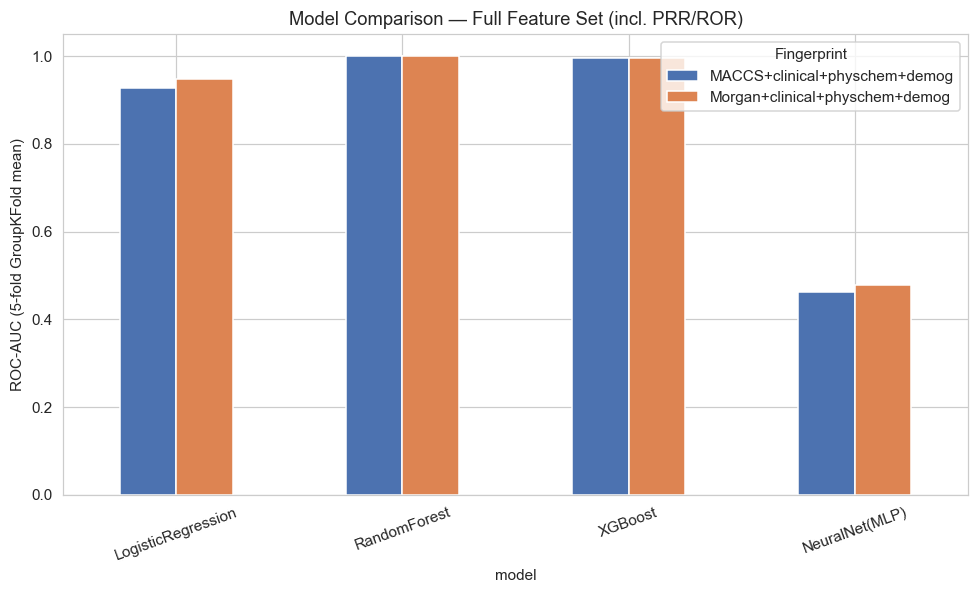

In [ ]:
# Plot combined model comparison for the full feature set, including PRR/ROR.
fig, ax = plt.subplots(figsize=(9, 5.5))
pivot = results_df.pivot(index="model", columns="fingerprint", values="roc_auc_mean")
pivot = pivot.loc[["LogisticRegression", "RandomForest", "XGBoost", "NeuralNet(MLP)"]]
pivot.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("ROC-AUC (5-fold GroupKFold mean)")
ax.set_title("Model Comparison — Full Feature Set (incl. PRR/ROR)")
ax.set_ylim(0, 1.05)
ax.legend(title="Fingerprint")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("figures/model_comparison_full.png", dpi=150)
plt.show()


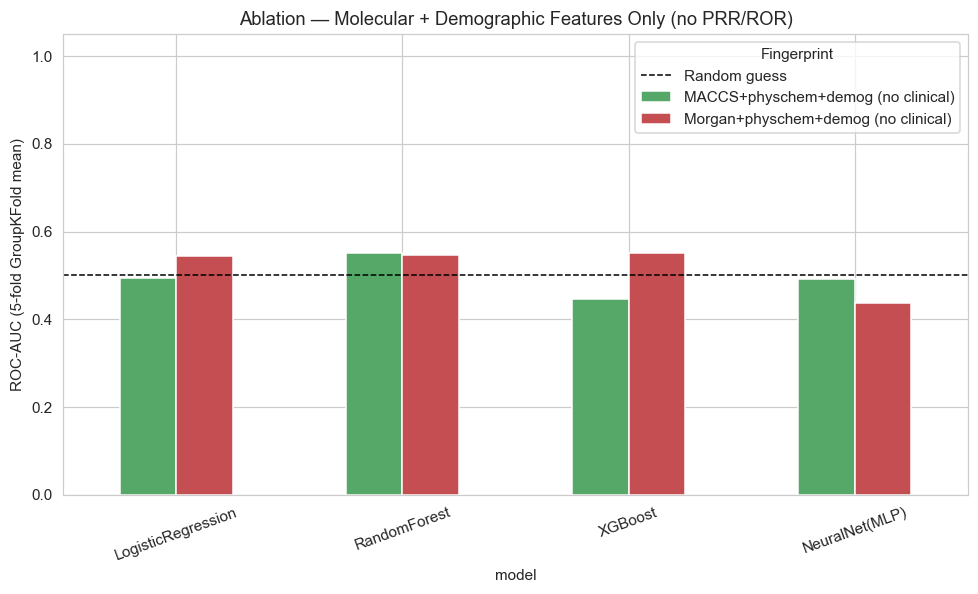

In [ ]:
# Plot the ablation results where PRR/ROR are removed from the feature set.
fig, ax = plt.subplots(figsize=(9, 5.5))
pivot2 = abl_results.pivot(index="model", columns="fingerprint", values="roc_auc_mean")
pivot2 = pivot2.loc[["LogisticRegression", "RandomForest", "XGBoost", "NeuralNet(MLP)"]]
pivot2.plot(kind="bar", ax=ax, color=["#55A868", "#C44E52"])
ax.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Random guess")
ax.set_ylabel("ROC-AUC (5-fold GroupKFold mean)")
ax.set_title("Ablation — Molecular + Demographic Features Only (no PRR/ROR)")
ax.set_ylim(0, 1.05)
ax.legend(title="Fingerprint")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("figures/model_comparison_ablation.png", dpi=150)
plt.show()


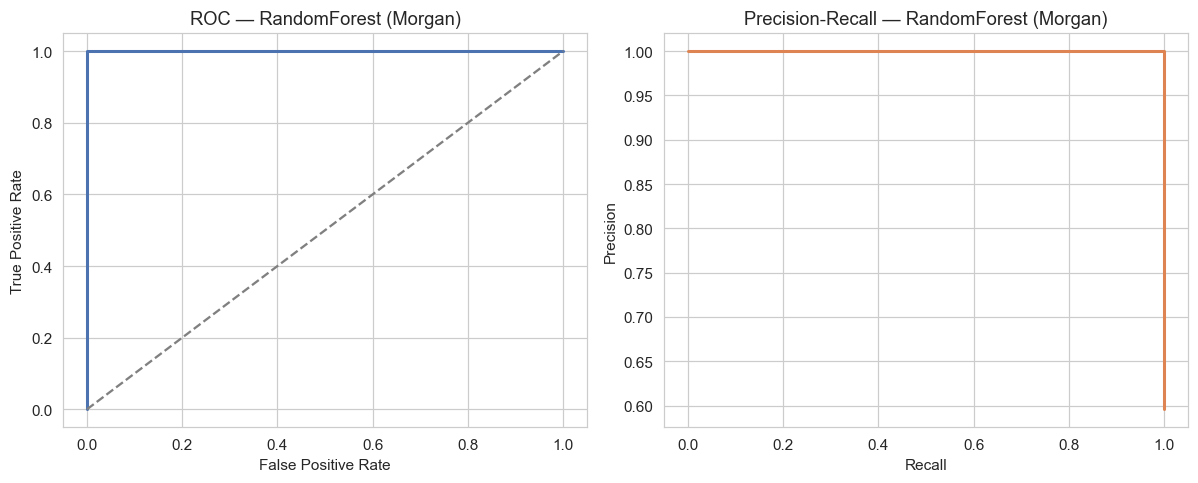

In [ ]:
# Aggregate the predictions from the winning model across all folds to visualize ROC and PR curves.
best = results_df.iloc[0]
sel = [p for p in fold_predictions if p["fingerprint"] == best["fingerprint"] and p["model"] == best["model"]]
y_true_all = sum([p["y_test"] for p in sel], [])
y_prob_all = sum([p["y_prob"] for p in sel], [])
fpr, tpr, _ = roc_curve(y_true_all, y_prob_all)
prec, rec, _ = precision_recall_curve(y_true_all, y_prob_all)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, color="#4C72B0", linewidth=2)
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title(f"ROC — {best['model']} ({best['fingerprint'].split('+')[0]})")
axes[1].plot(rec, prec, color="#DD8452", linewidth=2)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title(f"Precision-Recall — {best['model']} ({best['fingerprint'].split('+')[0]})")
plt.tight_layout()
plt.savefig("figures/roc_pr_curves_best_model.png", dpi=150)
plt.show()


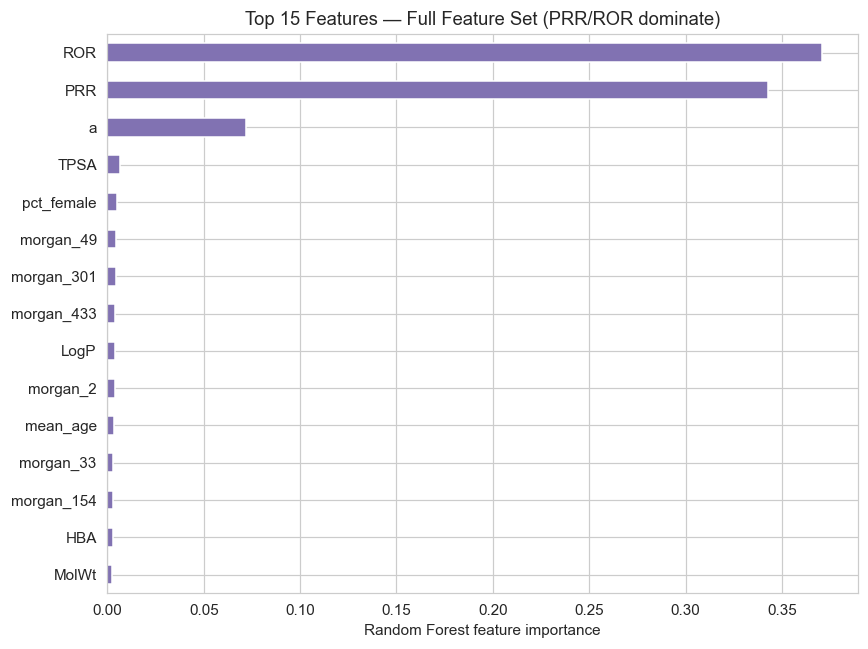

In [ ]:
# Plot the top-ranked feature importances for the best full-feature model.
fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15).iloc[::-1].plot(kind="barh", ax=ax, legend=False, color="#8172B2")
ax.set_xlabel("Random Forest feature importance")
ax.set_title("Top 15 Features — Full Feature Set (PRR/ROR dominate)")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=150)
plt.show()


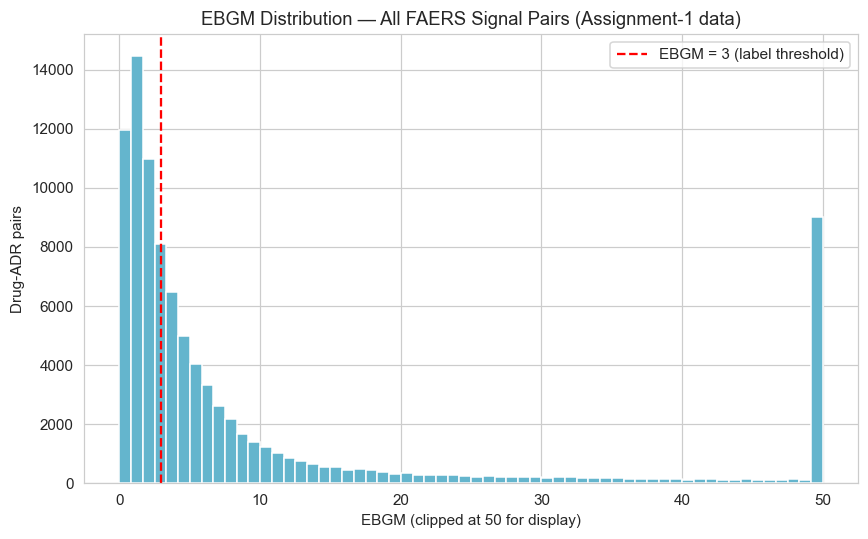

All figures saved to figures/: ['ebgm_distribution.png', 'feature_importance.png', 'model_comparison_ablation.png', 'model_comparison_full.png', 'roc_pr_curves_best_model.png']
All results saved to results/: ['FAERS_signals_with_EBGM.csv', 'ablation_no_clinical_features.csv', 'fold_predictions.json', 'ml_dataset_full.csv', 'model_comparison.csv', 'top_feature_importances.csv']


In [ ]:
# Final diagnostic plots: EBGM distribution and saved outputs summary.
fig, ax = plt.subplots(figsize=(8, 5))
vals = df["EBGM"].clip(upper=50)
ax.hist(vals, bins=60, color="#64B5CD", edgecolor="white")
ax.axvline(3, color="red", linestyle="--", linewidth=1.5, label="EBGM = 3 (label threshold)")
ax.set_xlabel("EBGM (clipped at 50 for display)")
ax.set_ylabel("Drug-ADR pairs")
ax.set_title("EBGM Distribution — All FAERS Signal Pairs (Assignment-1 data)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/ebgm_distribution.png", dpi=150)
plt.show()

print("All figures saved to figures/:", sorted(os.listdir("figures")))
print("All results saved to results/:", sorted(os.listdir("results")))
